# Part 1 — Plain CNN baseline

Simplest possible CNN trained from scratch on FGVC-Aircraft (100 variants). Every later design choice (BatchNorm, GAP, augmentation, residuals, …) gets added on top of this and must beat it on the **val** split.

Test split is only touched for final models (`RUN_TEST` at the bottom).

## Setup

In [ ]:
import os, json, time, math, random
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.datasets import FGVCAircraft
from torchvision.transforms import functional as TF
import matplotlib.pyplot as plt

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_ROOT = Path("/content/data")                            # fast local disk
    CACHE_DIR = Path("/content/drive/MyDrive/ipcv/cache")        # survives sessions
    RESULTS_DIR = Path("/content/drive/MyDrive/ipcv/results")
else:
    DATA_ROOT = Path.home() / "data" / "fgvc"                     # outside the repo
    CACHE_DIR = DATA_ROOT / "cache"
    RESULTS_DIR = Path("../results")

for d in (DATA_ROOT, CACHE_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
print("device:", DEVICE, "| torch", torch.__version__, "| torchvision", torchvision.__version__)

Mounted at /content/drive
device: cuda | torch 2.11.0+cu128 | torchvision 0.26.0+cu128


## Config

Everything that defines an experiment lives here, so later variants/ablations are just a different config. The training hyperparameters are also the ones Part 2A must reuse.

In [ ]:
config = dict(
    name="plain_cnn",
    seed=42,
    # data
    img_size=128,          # images resized to img_size x img_size
    crop_banner=True,      # FGVC images have a ~20px copyright banner at the bottom
    # model
    channels=(32, 64, 128, 256),
    # training
    optimizer="adam",
    lr=1e-3,
    weight_decay=0.0,
    batch_size=64,
    epochs=30,
)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(config["seed"])

## Data

Images are decoded and resized **once**, then cached as `uint8` tensors (~160 MB per split at 128px). Training reads straight from memory, which avoids JPEG decoding being the bottleneck on Colab's few CPU cores.

In [ ]:
BANNER_PX = 20

def load_split(split, img_size, crop_banner):
    tag = f"{split}_{img_size}{'_nobanner' if crop_banner else ''}.pt"
    path = CACHE_DIR / tag
    if path.exists():
        return torch.load(path)
    ds = FGVCAircraft(root=DATA_ROOT, split=split, annotation_level="variant", download=True)
    xs, ys = [], []
    for img, label in ds:
        if crop_banner:
            w, h = img.size
            img = img.crop((0, 0, w, h - BANNER_PX))
        img = TF.resize(img, [img_size, img_size], antialias=True)
        xs.append(TF.pil_to_tensor(img.convert("RGB")))
        ys.append(label)
    data = dict(x=torch.stack(xs), y=torch.tensor(ys), classes=ds.classes)
    torch.save(data, path)
    return data

t0 = time.time()
splits = {s: load_split(s, config["img_size"], config["crop_banner"]) for s in ("train", "val", "test")}
CLASSES = splits["train"]["classes"]
NUM_CLASSES = len(CLASSES)
print(f"loaded in {time.time() - t0:.0f}s | classes: {NUM_CLASSES}")
for s, d in splits.items():
    print(f"{s:5s} x={tuple(d['x'].shape)}  images/class ~ {len(d['y']) / NUM_CLASSES:.0f}")

100%|██████████| 2.75G/2.75G [02:03<00:00, 22.2MB/s]


loaded in 276s | classes: 100
train x=(3334, 3, 128, 128)  images/class ~ 33
val   x=(3333, 3, 128, 128)  images/class ~ 33
test  x=(3333, 3, 128, 128)  images/class ~ 33


Look at the data: random training images with their labels.

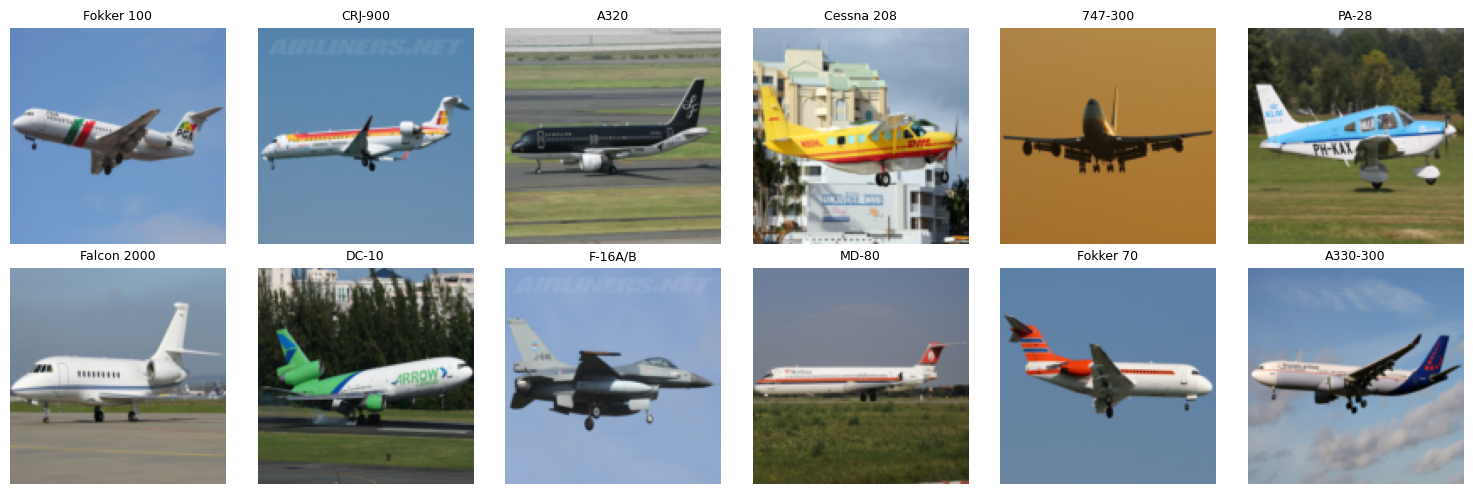

train images per class: min 33 max 34


In [ ]:
idx = torch.randperm(len(splits["train"]["y"]))[:12]
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for ax, i in zip(axes.flat, idx):
    ax.imshow(splits["train"]["x"][i].permute(1, 2, 0))
    ax.set_title(CLASSES[splits["train"]["y"][i]], fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

counts = torch.bincount(splits["train"]["y"], minlength=NUM_CLASSES)
print("train images per class: min", counts.min().item(), "max", counts.max().item())

Normalization statistics are computed on the **train** split only and applied to all splits.

In [ ]:
MEAN = splits["train"]["x"].float().div(255).mean(dim=(0, 2, 3))
STD = splits["train"]["x"].float().div(255).std(dim=(0, 2, 3))
print("mean", MEAN.tolist(), "std", STD.tolist())

def to_input(x_uint8):
    """uint8 batch on device -> normalized float batch."""
    x = x_uint8.float().div(255)
    return (x - MEAN.to(x.device)[:, None, None]) / STD.to(x.device)[:, None, None]

def batches(x, y, batch_size, shuffle):
    idx = torch.randperm(len(y)) if shuffle else torch.arange(len(y))
    for i in range(0, len(y), batch_size):
        b = idx[i:i + batch_size]
        yield x[b].to(DEVICE, non_blocking=True), y[b].to(DEVICE, non_blocking=True)

mean [0.4878549873828888, 0.5193531513214111, 0.5435032844543457] std [0.2109842449426651, 0.20293252170085907, 0.23612913489341736]


## Model: plain CNN

VGG-style stages of `Conv3x3 → ReLU → MaxPool2x2`: each stage halves the spatial resolution and doubles the channels. Then flatten + one linear classifier.

Deliberately **no** BatchNorm, no global average pooling, no dropout, no augmentation: those come later, one at a time.

In [ ]:
class PlainCNN(nn.Module):
    def __init__(self, channels, num_classes, img_size):
        super().__init__()
        layers, c_in = [], 3
        for c_out in channels:
            layers += [nn.Conv2d(c_in, c_out, kernel_size=3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c_out
        self.features = nn.Sequential(*layers)
        spatial = img_size // 2 ** len(channels)
        self.classifier = nn.Linear(c_in * spatial * spatial, num_classes)

    def forward(self, x):
        return self.classifier(torch.flatten(self.features(x), 1))

def build_model(cfg):
    return PlainCNN(cfg["channels"], NUM_CLASSES, cfg["img_size"]).to(DEVICE)

model = build_model(config)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"parameters: {n_params / 1e6:.2f}M")

PlainCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Linear(in_features=16384, out_features=100, bias=True)
)
parameters: 2.03M


## Training loop

In [ ]:
def make_optimizer(model, cfg):
    if cfg["optimizer"] == "adam":
        return torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    if cfg["optimizer"] == "sgd":
        return torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9, weight_decay=cfg["weight_decay"])
    raise ValueError(cfg["optimizer"])

@torch.no_grad()
def evaluate(model, data, batch_size=256):
    model.eval()
    loss_sum, correct = 0.0, 0
    for xb, yb in batches(data["x"], data["y"], batch_size, shuffle=False):
        logits = model(to_input(xb))
        loss_sum += F.cross_entropy(logits, yb, reduction="sum").item()
        correct += (logits.argmax(1) == yb).sum().item()
    n = len(data["y"])
    return loss_sum / n, correct / n

def train_one_epoch(model, opt, data, batch_size):
    model.train()
    loss_sum, correct, n = 0.0, 0, 0
    for xb, yb in batches(data["x"], data["y"], batch_size, shuffle=True):
        logits = model(to_input(xb))
        loss = F.cross_entropy(logits, yb)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        loss_sum += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(yb)
    return loss_sum / n, correct / n

def fit(cfg, train_data, val_data, verbose=True):
    set_seed(cfg["seed"])
    model = build_model(cfg)
    opt = make_optimizer(model, cfg)
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc")}
    best_acc, best_state = -1.0, None
    for epoch in range(1, cfg["epochs"] + 1):
        t0 = time.time()
        tl, ta = train_one_epoch(model, opt, train_data, cfg["batch_size"])
        vl, va = evaluate(model, val_data)
        for k, v in zip(hist, (tl, ta, vl, va)):
            hist[k].append(v)
        if va > best_acc:  # early stopping = keep the best-on-val weights
            best_acc, best_state = va, {k: v.detach().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"ep {epoch:3d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time() - t0:.1f}s")
    model.load_state_dict(best_state)
    return model, hist

## Sanity checks

1. **Initial loss** should be ≈ ln(100) ≈ 4.61: an untrained model should be uniformly unsure over 100 classes.
2. **Overfit a tiny subset** (100 images): if the model can't memorize them, something in the pipeline is broken.

In [ ]:
set_seed(config["seed"])
m = build_model(config)
init_loss, _ = evaluate(m, splits["val"])
print(f"initial val loss {init_loss:.3f}  (expected ~{math.log(NUM_CLASSES):.3f})")

tiny = {k: splits["train"][k][:100] for k in ("x", "y")}
m_tiny, h_tiny = fit({**config, "epochs": 60, "batch_size": 20}, tiny, tiny, verbose=False)
print(f"tiny subset: final train loss {h_tiny['train_loss'][-1]:.3f}, train acc {h_tiny['train_acc'][-1]:.2f}  (expected ~1.00)")

initial val loss 4.606  (expected ~4.605)
tiny subset: final train loss 0.000, train acc 1.00  (expected ~1.00)


## Train the baseline

In [ ]:
t0 = time.time()
model, hist = fit(config, splits["train"], splits["val"])
print(f"total {time.time() - t0:.0f}s | best val acc {max(hist['val_acc']):.3f} (epoch {int(np.argmax(hist['val_acc'])) + 1})")

ep   1 | train loss 4.594 acc 0.010 | val loss 4.514 acc 0.023 | 2.9s
ep   2 | train loss 4.407 acc 0.036 | val loss 4.389 acc 0.045 | 2.8s
ep   3 | train loss 4.044 acc 0.097 | val loss 4.183 acc 0.083 | 3.0s
ep   4 | train loss 3.436 acc 0.193 | val loss 4.148 acc 0.123 | 2.8s
ep   5 | train loss 2.657 acc 0.348 | val loss 4.258 acc 0.153 | 2.8s
ep   6 | train loss 1.882 acc 0.509 | val loss 4.538 acc 0.176 | 2.8s
ep   7 | train loss 1.188 acc 0.669 | val loss 5.082 acc 0.179 | 2.9s
ep   8 | train loss 0.674 acc 0.807 | val loss 6.845 acc 0.196 | 2.9s
ep   9 | train loss 0.301 acc 0.912 | val loss 8.093 acc 0.192 | 2.8s
ep  10 | train loss 0.218 acc 0.937 | val loss 9.298 acc 0.196 | 2.8s
ep  11 | train loss 0.108 acc 0.968 | val loss 10.286 acc 0.194 | 2.8s
ep  12 | train loss 0.068 acc 0.983 | val loss 11.422 acc 0.193 | 2.9s
ep  13 | train loss 0.074 acc 0.979 | val loss 11.739 acc 0.187 | 2.9s
ep  14 | train loss 0.058 acc 0.982 | val loss 12.077 acc 0.200 | 2.8s
ep  15 | train l

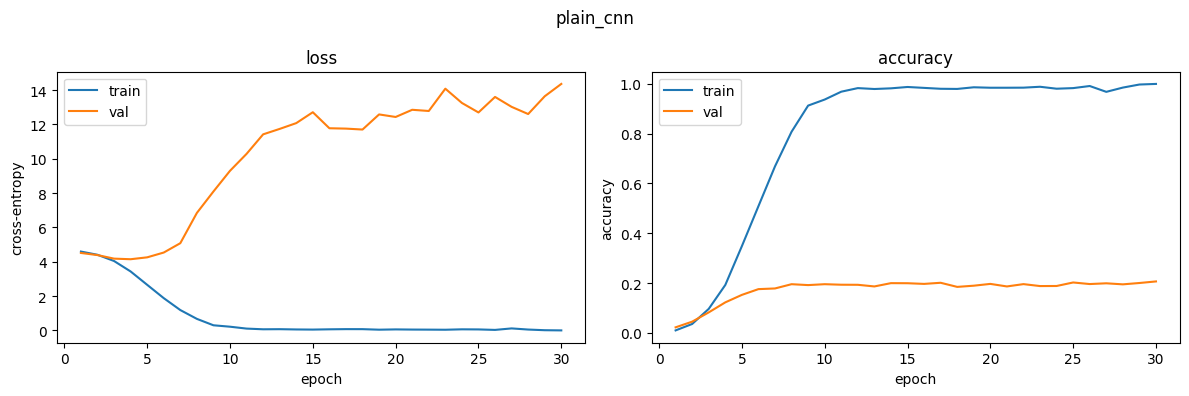

In [ ]:
def plot_history(hist, title):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
    a1.plot(ep, hist["train_loss"], label="train"); a1.plot(ep, hist["val_loss"], label="val")
    a1.set_xlabel("epoch"); a1.set_ylabel("cross-entropy"); a1.legend(); a1.set_title("loss")
    a2.plot(ep, hist["train_acc"], label="train"); a2.plot(ep, hist["val_acc"], label="val")
    a2.set_xlabel("epoch"); a2.set_ylabel("accuracy"); a2.legend(); a2.set_title("accuracy")
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_history(hist, config["name"])

Save config + curves to JSON so results survive a Colab disconnect and can be compared across experiments later.

In [ ]:
run = dict(config=config, history=hist, best_val_acc=max(hist["val_acc"]), params=n_params)
out = RESULTS_DIR / f"{config['name']}_seed{config['seed']}.json"
out.write_text(json.dumps(run, indent=2))
print("saved", out)

saved /content/drive/MyDrive/ipcv/results/plain_cnn_seed42.json


## Test (final models only)

In [ ]:
RUN_TEST = False
if RUN_TEST:
    test_loss, test_acc = evaluate(model, splits["test"])
    print(f"test acc {test_acc:.3f}")